# TỔNG HỢP VÀ SO SÁNH SỨC KHỎE TÂM THẦN Ở THANH THIẾU NIÊN TẠI BA QUỐC GIA

## 1. Mục tiêu

Notebook này tổng hợp kết quả phân tích dữ liệu sức khỏe tâm thần ở thanh thiếu niên tại Bhutan, Morocco và Các Tiểu vương quốc Ả Rập Thống nhất (UAE).

Các nội dung chính gồm:
- Thống kê và so sánh dữ liệu của ba quốc gia.
- So sánh tỷ lệ trả lời Có/Không đối với câu hỏi Q24.
- So sánh kết quả các mô hình Machine Learning.
- Trực quan hóa kết quả và đưa ra nhận xét chung.

Đọc file dữ liệu

In [2]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Vì notebook nằm trong thư mục notebooks/
PROJECT_DIR = Path("..")
DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Đường dẫn dữ liệu
DATA_FILES = {
    "Bhutan": DATA_DIR / "2016BTN (National).csv",
    "Morocco": DATA_DIR / "2016MAR (National).csv",
    "UAE": DATA_DIR / "ARE2016 (National).csv",
}

# Kiểm tra và đọc dữ liệu
country_data = {}

for country, path in DATA_FILES.items():
    if not path.exists():
        raise FileNotFoundError(
            f"Không tìm thấy file {path.resolve()}"
        )

    country_data[country] = pd.read_csv(
        path,
        low_memory=False
    )

print("ĐÃ ĐỌC DỮ LIỆU THÀNH CÔNG!")

for country, df in country_data.items():
    print(f"{country}: {df.shape[0]} dòng, {df.shape[1]} cột")

ĐÃ ĐỌC DỮ LIỆU THÀNH CÔNG!
Bhutan: 7576 dòng, 141 cột
Morocco: 6745 dòng, 141 cột
UAE: 5849 dòng, 141 cột


## 2. THỐNG KÊ TỔNG QUAN DỮ LIỆU

Phần này trình bày quy mô dữ liệu, số lượng biến và tình trạng dữ liệu thiếu của ba quốc gia Bhutan, Morocco và UAE. Qua đó, đánh giá tổng quan chất lượng dữ liệu trước khi tiến hành so sánh.

In [3]:
summary_data = []

for country, df in country_data.items():
    summary_data.append({
        "Quốc gia": country,
        "Số bản ghi": len(df),
        "Số biến": df.shape[1],
        "Số ô dữ liệu thiếu": int(df.isna().sum().sum()),
        "Tỷ lệ ô dữ liệu thiếu (%)": round(
            df.isna().sum().sum() / df.size * 100, 2
        ) if df.size else 0
    })

summary_df = pd.DataFrame(summary_data)

display(summary_df)

,Quốc gia,Số bản ghi,Số biến,Số ô dữ liệu thiếu,Tỷ lệ ô dữ liệu thiếu (%)
0,Bhutan,7576,141,169237,15.84
1,Morocco,6745,141,237156,24.94
2,UAE,5849,141,236818,28.72


## 3. SO SÁNH TỶ LỆ TRẢ LỜI Q24 GIỮA BA QUỐC GIA

Q24 là câu hỏi khảo sát về việc người tham gia có nghiêm túc nghĩ đến việc tự tử trong 12 tháng qua hay không.

- Q24 = 1: Có.
- Q24 = 2: Không.

Phần này thống kê số câu trả lời hợp lệ, tỷ lệ Có, tỷ lệ Không và số câu trả lời thiếu hoặc không hợp lệ tại mỗi quốc gia. Các giá trị thiếu không được tự động xem là câu trả lời Không.

In [4]:
import re

def find_question_column(df, question_number):
    column_map = {
        re.sub(r"[^a-z0-9]", "", str(col).lower()): col
        for col in df.columns
    }

    for candidate in [
        f"Q{question_number}",
        f"QN{question_number}"
    ]:
        key = re.sub(r"[^a-z0-9]", "", candidate.lower())

        if key in column_map:
            return column_map[key]

    raise KeyError(
        f"Không tìm thấy Q{question_number}/QN{question_number}"
    )


q24_results = []

for country, df in country_data.items():
    q24_col = find_question_column(df, 24)
    q24 = pd.to_numeric(df[q24_col], errors="coerce")

    # Chỉ giữ câu trả lời hợp lệ
    valid = q24[q24.isin([1, 2])]

    yes_count = int((valid == 1).sum())
    no_count = int((valid == 2).sum())
    valid_count = len(valid)

    q24_results.append({
        "Quốc gia": country,
        "Số câu trả lời hợp lệ": valid_count,
        "Số trả lời Có": yes_count,
        "Số trả lời Không": no_count,
        "Tỷ lệ Có (%)": round(
            yes_count / valid_count * 100, 2
        ) if valid_count else np.nan,
        "Tỷ lệ Không (%)": round(
            no_count / valid_count * 100, 2
        ) if valid_count else np.nan,
        "Số câu trả lời thiếu/không hợp lệ": len(df) - valid_count
    })

q24_summary = pd.DataFrame(q24_results)

display(q24_summary)

# Lưu bảng
q24_summary.to_csv(
    RESULTS_DIR / "bang_Q24_3_quoc_gia.csv",
    index=False,
    encoding="utf-8-sig"
)

,Quốc gia,Số câu trả lời hợp lệ,Số trả lời Có,Số trả lời Không,Tỷ lệ Có (%),Tỷ lệ Không (%),Số câu trả lời thiếu/không hợp lệ
0,Bhutan,7487,862,6625,11.51,88.49,89
1,Morocco,6427,1031,5396,16.04,83.96,318
2,UAE,3370,492,2878,14.60,85.40,2479


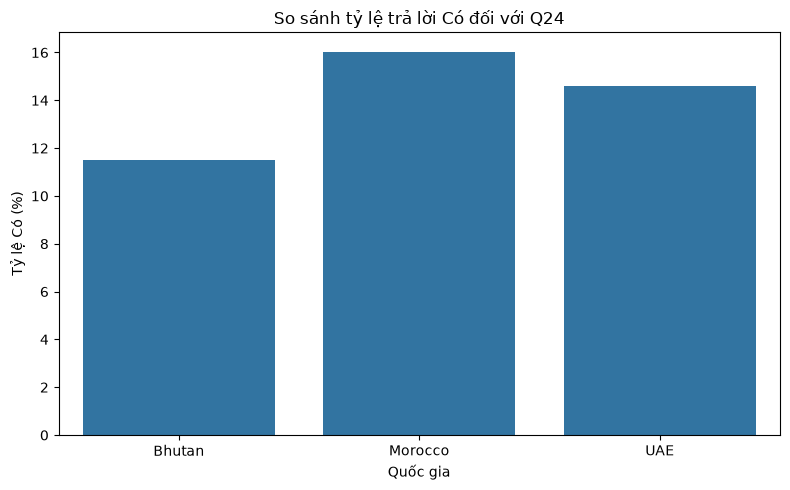

In [5]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=q24_summary,
    x="Quốc gia",
    y="Tỷ lệ Có (%)"
)

plt.title("So sánh tỷ lệ trả lời Có đối với Q24")
plt.xlabel("Quốc gia")
plt.ylabel("Tỷ lệ Có (%)")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "ty_le_Q24.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [6]:
from pathlib import Path

RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Thư mục lưu kết quả:", RESULTS_DIR.resolve())

Thư mục lưu kết quả: D:\BaoCaoPython\Python_report\results


## 4. TỔNG HỢP VÀ SO SÁNH CÁC MÔ HÌNH MACHINE LEARNING

Phần này tổng hợp kết quả đánh giá các mô hình Logistic Regression, Decision Tree, Random Forest, Gradient Boosting và Neural Network (MLP) trên dữ liệu của ba quốc gia Bhutan, Morocco và UAE.

Các chỉ số được sử dụng gồm Accuracy, Precision, Recall, F1-score và ROC-AUC. Kết quả giúp đánh giá khả năng phân loại của từng mô hình trên từng bộ dữ liệu.

In [7]:
from pathlib import Path
import pandas as pd

# Đường dẫn thư mục kết quả
RESULTS_DIR = Path("../results")

# Ba file kết quả đã xuất từ các notebook riêng
result_files = {
    "Bhutan": RESULTS_DIR / "bhutan_model_comparison.csv",
    "Morocco": RESULTS_DIR / "morocco_model_comparison.csv",
    "UAE": RESULTS_DIR / "uae_model_comparison.csv"
}

# Kiểm tra các file có tồn tại không
for country, file_path in result_files.items():
    if not file_path.exists():
        raise FileNotFoundError(
            f"Chưa tìm thấy file kết quả {country}: "
            f"{file_path.resolve()}\n"
            "Hãy kiểm tra lại Bước 6."
        )

# Đọc từng bảng kết quả
model_results = []

for country, file_path in result_files.items():
    df_result = pd.read_csv(file_path)

    # Thêm cột quốc gia
    df_result["Quốc gia"] = country

    model_results.append(df_result)

# Ghép ba bảng thành một bảng chung
all_model_results = pd.concat(
    model_results,
    ignore_index=True
)

print("Đã tổng hợp kết quả mô hình!")
print("Số dòng:", len(all_model_results))

display(all_model_results)

Đã tổng hợp kết quả mô hình!
Số dòng: 15


,Mô hình,Accuracy,Precision,Recall,F1-score,ROC-AUC,Quốc gia
0,Random Forest,0.745661,0.225722,0.500000,0.311031,0.670499,Bhutan
1,Decision Tree,0.684913,0.195122,0.558140,0.289157,0.648782,Bhutan
2,Logistic Regression,0.664887,0.188679,0.581395,0.284900,0.685709,Bhutan
3,Gradient Boosting,0.883845,0.333333,0.011628,0.022472,0.687717,Bhutan
4,Neural Network (MLP),0.884513,0.000000,0.000000,0.000000,0.678202,Bhutan
5,Random Forest,0.763608,0.347826,0.543689,0.424242,0.731976,Morocco
6,Logistic Regression,0.706843,0.298824,0.616505,0.402536,0.728106,Morocco
7,Decision Tree,0.716174,0.286863,0.519417,0.369603,0.678953,Morocco
8,Neural Network (MLP),0.842924,0.533333,0.155340,0.240602,0.730699,Morocco
9,Gradient Boosting,0.840591,0.509091,0.135922,0.214559,0.729200,Morocco


In [8]:
print("Các cột hiện có:")
print(all_model_results.columns.tolist())

Các cột hiện có:
['Mô hình', 'Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC', 'Quốc gia']


In [9]:
all_model_results.to_csv(
    RESULTS_DIR / "bang_tong_hop_3_quoc_gia.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu bảng tổng hợp 3 quốc gia!")

Đã lưu bảng tổng hợp 3 quốc gia!


## 5. SO SÁNH HIỆU QUẢ MÔ HÌNH

Phần này so sánh hiệu quả của các mô hình trên từng quốc gia trước khi lựa chọn mô hình tốt nhất.
- F1-score phản ánh sự cân bằng giữa Precision và Recall.
- Recall cho biết tỷ lệ trường hợp thuộc lớp dương tính được mô hình nhận diện đúng. Cần xác nhận cách tính Recall trong các file kết quả của từng quốc gia, đặc biệt lớp nào được xem là dương tính.

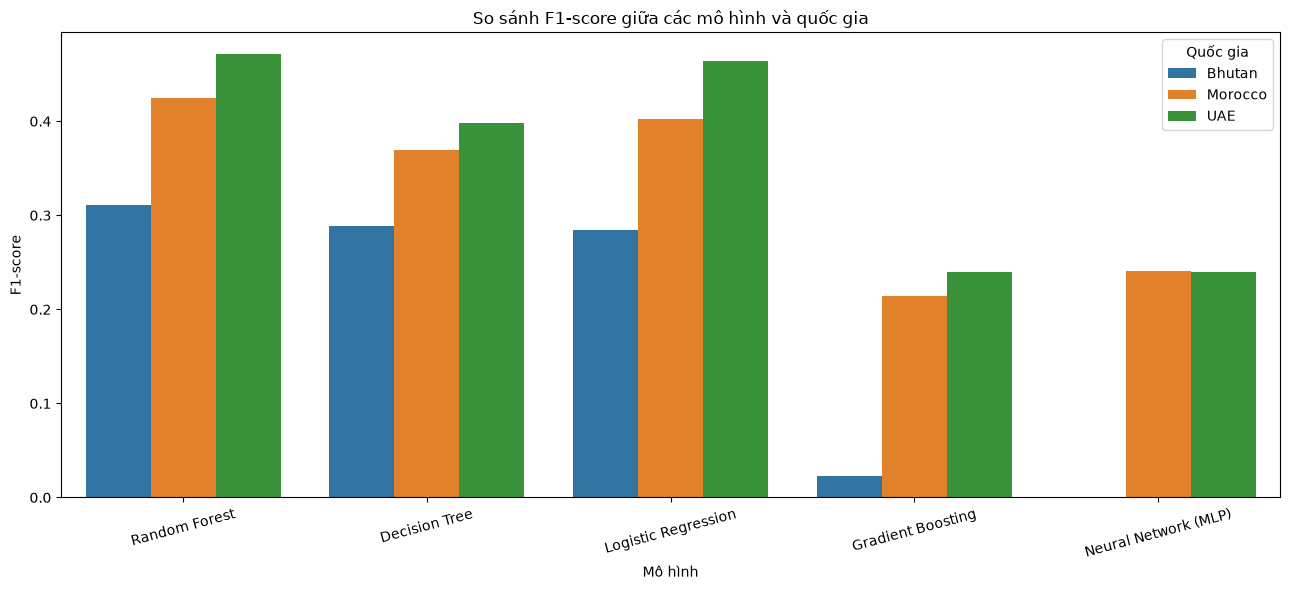

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Kiểm tra cột cần thiết
required_columns = {"Quốc gia", "Mô hình", "F1-score"}

missing_columns = required_columns - set(all_model_results.columns)

if missing_columns:
    raise ValueError(
        f"Thiếu cột: {missing_columns}. "
        "Hãy kiểm tra lại tên cột ở Bước 8."
    )

# Chuyển F1-score thành số
all_model_results["F1-score"] = pd.to_numeric(
    all_model_results["F1-score"],
    errors="coerce"
)

plot_data = all_model_results.dropna(
    subset=["F1-score"]
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=plot_data,
    x="Mô hình",
    y="F1-score",
    hue="Quốc gia"
)

plt.title("So sánh F1-score giữa các mô hình và quốc gia")
plt.xlabel("Mô hình")
plt.ylabel("F1-score")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "so_sanh_F1_score.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

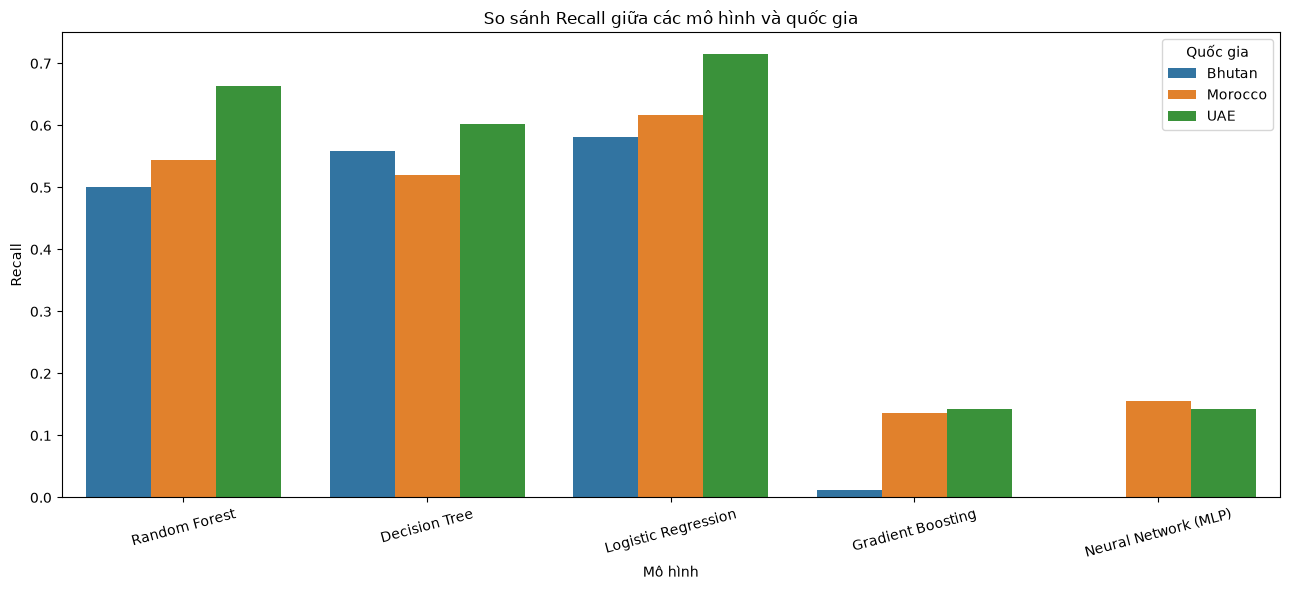

In [11]:
all_model_results["Recall"] = pd.to_numeric(
    all_model_results["Recall"],
    errors="coerce"
)

recall_data = all_model_results.dropna(
    subset=["Recall"]
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=recall_data,
    x="Mô hình",
    y="Recall",
    hue="Quốc gia"
)

plt.title("So sánh Recall giữa các mô hình và quốc gia")
plt.xlabel("Mô hình")
plt.ylabel("Recall")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "so_sanh_Recall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6. XÁC ĐỊNH MÔ HÌNH CÓ F1-SCORE CAO NHẤT

Trong phần này, các mô hình được xếp hạng theo F1-score riêng cho từng quốc gia. Kết quả được sử dụng để xác định mô hình có sự cân bằng tốt nhất giữa Precision và Recall trong từng bộ dữ liệu.

In [12]:
valid_results = all_model_results.dropna(
    subset=["F1-score"]
).copy()

if valid_results.empty:
    print("Không có F1-score hợp lệ để so sánh.")
else:
    best_indices = (
        valid_results.groupby("Quốc gia")["F1-score"].idxmax()
    )

    best_models = (
        valid_results.loc[best_indices]
        .sort_values("Quốc gia")
        .reset_index(drop=True)
    )

    display(best_models)

,Mô hình,Accuracy,Precision,Recall,F1-score,ROC-AUC,Quốc gia
0,Random Forest,0.745661,0.225722,0.500000,0.311031,0.670499,Bhutan
1,Random Forest,0.763608,0.347826,0.543689,0.424242,0.731976,Morocco
2,Random Forest,0.783383,0.365169,0.663265,0.471014,0.784891,UAE


## 7. PHÂN TÍCH KẾT QUẢ CỦA CÁC MÔ HÌNH ĐƯỢC CHỌN
Khác với phần 6 chỉ chọn mô hình theo F1-score, phần này xem xét các chỉ số của chính những mô hình đã được chọn ở từng quốc gia. Bảng và biểu đồ được tạo trực tiếp từ best_models, không nhập số liệu minh họa thủ công, nhằm tránh sai lệch với kết quả thực nghiệm.

BẢNG CHỈ SỐ CỦA MÔ HÌNH ĐƯỢC CHỌN Ở TỪNG QUỐC GIA


,Quốc gia,Mô hình,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Bhutan,Random Forest,0.7457,0.2257,0.5000,0.3110,0.6705
1,Morocco,Random Forest,0.7636,0.3478,0.5437,0.4242,0.7320
2,UAE,Random Forest,0.7834,0.3652,0.6633,0.4710,0.7849


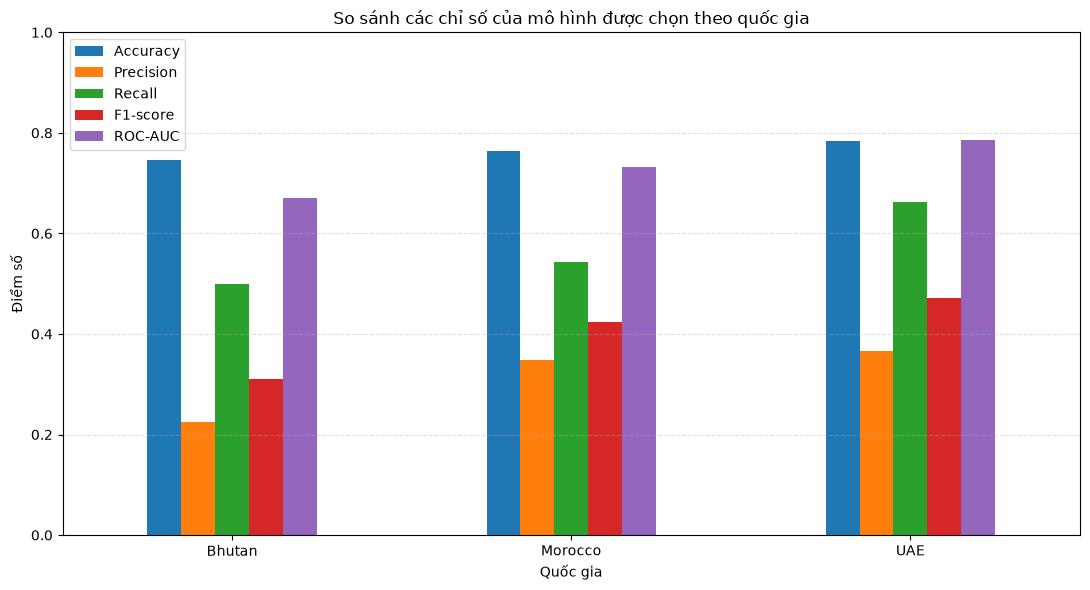


TÓM TẮT MÔ HÌNH ĐƯỢC CHỌN
Bhutan: chọn Random Forest; F1-score = 0.3110; Accuracy = 0.7457.
Morocco: chọn Random Forest; F1-score = 0.4242; Accuracy = 0.7636.
UAE: chọn Random Forest; F1-score = 0.4710; Accuracy = 0.7834.


In [15]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

if "best_models" not in globals() or best_models.empty:
    raise ValueError("Chưa có best_models. Hãy chạy lần lượt các mục 1–6 trước.")

# Chỉ hiển thị các chỉ số thật sự có trong bảng kết quả
preferred_columns = [
    "Quốc gia", "Mô hình", "Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"
]
available_columns = [c for c in preferred_columns if c in best_models.columns]
best_models_report = best_models[available_columns].copy()

metric_columns = [c for c in ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"] if c in best_models_report.columns]
for col in metric_columns:
    best_models_report[col] = pd.to_numeric(best_models_report[col], errors="coerce")

print("BẢNG CHỈ SỐ CỦA MÔ HÌNH ĐƯỢC CHỌN Ở TỪNG QUỐC GIA")
display(best_models_report.style.format({c: "{:.4f}" for c in metric_columns}))

# Biểu đồ so sánh các chỉ số của mô hình được chọn
plot_metrics = [c for c in ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"] if c in best_models_report.columns]
if plot_metrics:
    chart_data = best_models_report.set_index("Quốc gia")[plot_metrics]
    chart_data.plot(kind="bar", figsize=(11, 6), ylim=(0, 1), rot=0)
    plt.title("So sánh các chỉ số của mô hình được chọn theo quốc gia")
    plt.xlabel("Quốc gia")
    plt.ylabel("Điểm số")
    plt.grid(axis="y", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "phan_tich_mo_hinh_duoc_chon.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("Không tìm thấy các cột chỉ số số học để vẽ biểu đồ.")

# Tóm tắt mô hình được chọn; không tự suy diễn chỉ số chưa có trong dữ liệu
print("\nTÓM TẮT MÔ HÌNH ĐƯỢC CHỌN")
for _, row in best_models_report.iterrows():
    parts = [f"{row['Quốc gia']}: chọn {row['Mô hình']}"]
    if "F1-score" in best_models_report.columns and pd.notna(row.get("F1-score")):
        parts.append(f"F1-score = {row['F1-score']:.4f}")
    if "Accuracy" in best_models_report.columns and pd.notna(row.get("Accuracy")):
        parts.append(f"Accuracy = {row['Accuracy']:.4f}")
    print("; ".join(parts) + ".")


## 8. NHẬN XÉT VÀ KẾT LUẬN

### 8.1. Nhận xét kết quả phân tích

Nghiên cứu tổng hợp dữ liệu của thanh thiếu niên tại Bhutan, Morocco và Các Tiểu vương quốc Ả Rập Thống nhất (UAE). Trước tiên, notebook thống kê quy mô dữ liệu và tình trạng dữ liệu thiếu; tiếp theo, so sánh tỷ lệ câu trả lời hợp lệ của Q24; sau đó tổng hợp và so sánh các mô hình Machine Learning bằng những chỉ số có trong các file kết quả.

Biểu đồ ở mục 5 giúp so sánh hiệu quả các mô hình trên từng bộ dữ liệu. Mục 6 chọn mô hình có F1-score cao nhất theo từng quốc gia, còn mục 7 phân tích các chỉ số của những mô hình được chọn. Khi diễn giải kết quả, cần kiểm tra định nghĩa lớp dương tính và cách tính các chỉ số trong từng notebook huấn luyện; không nên kết luận chỉ dựa trên Accuracy.

### 8.2. Kết luận

Notebook xây dựng một quy trình thống nhất để mô tả dữ liệu, so sánh tỷ lệ trả lời Q24, tổng hợp kết quả mô hình và lựa chọn mô hình theo F1-score trong từng quốc gia. Kết luận cụ thể về quốc gia hoặc mô hình nào có hiệu quả tốt hơn cần căn cứ vào bảng kết quả và biểu đồ được tạo khi chạy notebook, không nên ghi trước các con số chưa được xác minh.

Các mô hình chỉ học những mối liên hệ thống kê trong dữ liệu được cung cấp. Dự đoán Q24 không chứng minh quan hệ nhân quả, không thay thế đánh giá chuyên môn và không được sử dụng như một chẩn đoán sức khỏe tâm thần cá nhân.

### 8.3. Hạn chế của nghiên cứu

- Dữ liệu giữa các quốc gia có thể khác nhau về quy mô, đặc điểm người tham gia và cách thu thập.
- Dữ liệu thiếu, cách mã hóa câu trả lời và sự mất cân bằng giữa các lớp có thể ảnh hưởng đến kết quả.
- Hiệu suất phụ thuộc vào các biến đầu vào, cách chia tập dữ liệu và tham số của mô hình.
- So sánh chỉ số giữa các quốc gia cần thận trọng; chỉ số phải được tính cùng một cách và trên các tập đánh giá tương đương.

### 8.4. Hướng phát triển
- Kiểm tra thống nhất cách mã hóa biến mục tiêu và cách tính Precision, Recall, F1-score ở cả ba notebook.
- Tối ưu hóa tham số và sử dụng đánh giá chéo khi phù hợp.
- Đánh giá trên dữ liệu độc lập và phân tích thêm ma trận nhầm lẫn.
- Mở rộng dữ liệu và phân tích các yếu tố liên quan một cách thận trọng, không diễn giải tương quan thành quan hệ nhân quả.